In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
POLLUTANTS = ["pm25", "pm10"]
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2

WEATHER_MODES = {
    "same_day": "same-day observed weather (nowcast / association)",
    "t_minus_1": "weather from day t-1 (true forecast)",
}

SCALED_MODELS = {"Ridge", "Lasso"}


In [3]:
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")


In [4]:
def get_weather_cols(df):
    return [
        col for col in df.columns
        if (col.startswith(("temperature", "relative_humidity", "dew_point",
                            "apparent_temperature", "pressure", "surface_pressure",
                            "precipitation", "rain_sum", "snowfall", "cloud_cover",
                            "shortwave", "direct_radiation", "diffuse_radiation",
                            "global_tilted", "sunshine", "wind", "et0",
                            "weather_code", "snow_depth", "vapour_pressure", "soil_"))
            and col != "wind_category")
    ]


In [5]:
def load_weather_daily(weather_cols):
    hourly = pd.read_parquet(RAW_DIR / "weather_hourly_skopje_2016_2025.parquet")
    hourly["date"] = pd.to_datetime(hourly["time"]).dt.normalize()

    def mode_or_nan(values):
        values = values.dropna()
        return values.mode().iloc[0] if not values.empty else np.nan

    stat_funcs = {"mean": "mean", "min": "min", "max": "max", "sum": "sum", "mode": mode_or_nan,
                  "u": lambda s: np.sin(np.deg2rad(s)).mean(),
                  "v": lambda s: np.cos(np.deg2rad(s)).mean()}

    agg_map = {}
    for daily_col in weather_cols:
        base, _, stat = daily_col.rpartition("_")
        if stat in stat_funcs and base in hourly.columns:
            agg_map[daily_col] = (base, stat_funcs[stat])

    missing = [col for col in weather_cols if col not in agg_map]
    if missing:
        raise ValueError(f"Cannot rebuild from raw hourly weather: {missing}")

    weather_daily = (
        hourly.groupby("date")
        .agg(**{name: pd.NamedAgg(col, func) for name, (col, func) in agg_map.items()})
        .sort_index()
    )
    return weather_daily


In [6]:
def build_feature_matrix(df, pollutant, weather_mode, weather_daily):
    lag_cols = [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS]
    rolling_cols = [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS]
    rolling_std_cols = [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS]
    calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
    weather_cols = get_weather_cols(df)

    base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
    required = base_cols + ["date", "station_id", pollutant]

    if weather_mode == "t_minus_1":
        lagged = weather_daily.shift(1, freq="D")
        df = df.drop(columns=weather_cols + ["rain_indicator", "wind_category"])
        df = df.merge(lagged[weather_cols], left_on="date", right_index=True, how="left")
        df["rain_indicator"] = (df["precipitation_sum"] > 0).astype(int)
        df["wind_category"] = pd.cut(df["wind_speed_10m_mean"], bins=[-np.inf, 2, 5, np.inf],
                                     labels=["weak", "moderate", "strong"])

    model_df = df.dropna(subset=required).copy().reset_index(drop=True)
    model_df = model_df.sort_values("date").reset_index(drop=True)

    wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")
    X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
    y = model_df[pollutant].astype(float)

    return model_df, X, y


In [7]:
def chronological_split(model_df, X, y):
    cutoff = model_df["date"].quantile(1 - TEST_FRACTION)
    split_idx = int((model_df["date"] < cutoff).sum())

    shared_dates = set(model_df["date"].iloc[:split_idx]) & set(model_df["date"].iloc[split_idx:])
    train_share = split_idx / len(model_df)

    print(f"Modelling rows: {len(model_df):,}  ({train_share:.0%} train / {1 - train_share:.0%} test)")
    print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
    print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")
    print(f"Dates shared across train/test: {len(shared_dates)} (split is by whole dates, cutoff={pd.Timestamp(cutoff).date()})")

    return X.iloc[:split_idx], X.iloc[split_idx:], y.iloc[:split_idx], y.iloc[split_idx:], split_idx


In [8]:
def evaluate_regression(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


In [9]:
def make_models():
    return {
        "LinearRegression": LinearRegression(),
        "Ridge": Ridge(alpha=1.0),
        "Lasso": Lasso(alpha=1.0, max_iter=10000),
        "DecisionTree": DecisionTreeRegressor(random_state=42),
        "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
        "GradientBoosting": GradientBoostingRegressor(random_state=42),
    }


In [10]:
data = {}

for pollutant in POLLUTANTS:
    df = pd.read_parquet(PROCESSED_DIR / f"features_{pollutant}.parquet")
    df["date"] = pd.to_datetime(df["date"])
    weather_daily = load_weather_daily(get_weather_cols(df))

    for weather_mode in WEATHER_MODES:
        model_df, X, y = build_feature_matrix(df, pollutant, weather_mode, weather_daily)
        data[(pollutant, weather_mode)] = {"model_df": model_df, "X": X, "y": y}
        print(f"{pollutant.upper()} [{weather_mode}]: {len(model_df):,} rows, {X.shape[1]} features")

    n_rows = {mode: len(data[(pollutant, mode)]["model_df"]) for mode in WEATHER_MODES}
    print(f"{pollutant.upper()}: rows identical across weather modes = {len(set(n_rows.values())) == 1}")


PM25 [same_day]: 1,888 rows, 61 features
PM25 [t_minus_1]: 1,888 rows, 61 features
PM25: rows identical across weather modes = True


PM10 [same_day]: 3,575 rows, 61 features
PM10 [t_minus_1]: 3,575 rows, 61 features
PM10: rows identical across weather modes = True


In [11]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        print(f"\n{pollutant.upper()} | {WEATHER_MODES[weather_mode]}")

        entry = data[(pollutant, weather_mode)]
        X_train, X_test, y_train, y_test, split_idx = chronological_split(entry["model_df"], entry["X"], entry["y"])
        entry.update({"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test, "split_idx": split_idx})



PM25 | same-day observed weather (nowcast / association)
Modelling rows: 1,888  (80% train / 20% test)
Train period: 2018-04-26 .. 2024-07-19
Test period : 2024-07-20 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-07-20)

PM25 | weather from day t-1 (true forecast)
Modelling rows: 1,888  (80% train / 20% test)
Train period: 2018-04-26 .. 2024-07-19
Test period : 2024-07-20 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-07-20)

PM10 | same-day observed weather (nowcast / association)
Modelling rows: 3,575  (80% train / 20% test)
Train period: 2016-12-18 .. 2024-03-06
Test period : 2024-03-07 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-03-07)

PM10 | weather from day t-1 (true forecast)
Modelling rows: 3,575  (80% train / 20% test)
Train period: 2016-12-18 .. 2024-03-06
Test period : 2024-03-07 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, c

In [12]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        models = make_models()
        scaler = StandardScaler().fit(entry["X_train"])

        results = {}
        predictions = {}

        for name, model in models.items():
            if name in SCALED_MODELS:
                x_train = scaler.transform(entry["X_train"])
                x_test = scaler.transform(entry["X_test"])
            else:
                x_train, x_test = entry["X_train"], entry["X_test"]

            model.fit(x_train, entry["y_train"])
            pred = model.predict(x_test)
            results[name] = evaluate_regression(entry["y_test"], pred)
            predictions[name] = pred

        persistence = entry["model_df"][pollutant + "_lag_1"].iloc[entry["split_idx"]:]
        results["Persistence(lag1)"] = evaluate_regression(entry["y_test"], persistence)
        predictions["Persistence(lag1)"] = persistence.to_numpy()

        entry.update({"models": models, "results": results, "predictions": predictions})


In [13]:
results_by_key = {}

for key, entry in data.items():
    results_df = pd.DataFrame(entry["results"]).T
    results_by_key[key] = results_df.reindex(results_df["RMSE"].sort_values().index)

display(pd.concat(results_by_key, names=["pollutant", "weather_mode", "model"]).round(3))

for pollutant in POLLUTANTS:
    same_day = results_by_key[(pollutant, "same_day")]
    t_minus_1 = results_by_key[(pollutant, "t_minus_1")]
    best_rmse = same_day["RMSE"].min()
    forecast_rmse = t_minus_1["RMSE"].min()

    print(f"\n{pollutant.upper()}: best RMSE same-day weather = {best_rmse:.2f} ({same_day['RMSE'].idxmin()})")
    print(f"{pollutant.upper()}: best RMSE t-1 weather      = {forecast_rmse:.2f} ({t_minus_1['RMSE'].idxmin()})")
    print(f"{pollutant.upper()}: true forecast degrades RMSE by {(forecast_rmse - best_rmse) / best_rmse * 100:+.1f}%")


RMSE     MAE     R2
pollutant weather_mode model                                   
pm25      same_day     LinearRegression   13.201   8.665  0.751
                       Lasso              13.328   8.527  0.746
                       Persistence(lag1)  14.621   8.702  0.695
                       Ridge              14.786  10.386  0.688
                       RandomForest       15.224  10.771  0.669
                       GradientBoosting   15.970  11.575  0.636
                       DecisionTree       22.034  12.589  0.307
          t_minus_1    Lasso              14.170   8.753  0.713
                       LinearRegression   14.227   9.022  0.711
                       Ridge              14.436   9.221  0.702
                       Persistence(lag1)  14.621   8.702  0.695
                       RandomForest       15.841  11.435  0.642
                       GradientBoosting   20.112  14.877  0.422
                       DecisionTree       23.201  12.922  0.231
pm10      same_day     RandomForest       14.162   8.621  0.809
                       GradientBoosting   14.204   9.055  0.808
                       LinearRegression   14.232  10.257  0.807
                       Ridge              14.333  10.370  0.804
                       Lasso              14.340   9.974  0.804
                       Persistence(lag1)  15.156   9.415  0.781
                       DecisionTree       21.596  12.550  0.555
          t_minus_1    Ridge              14.926   9.932  0.788
                       Lasso              14.940   9.566  0.787
                       LinearRegression   15.099   9.976  0.783
                       Persistence(lag1)  15.156   9.415  0.781
                       RandomForest       15.523   9.157  0.770
                       GradientBoosting   15.638   9.404  0.767
                       DecisionTree       21.773  12.744  0.548


PM25: best RMSE same-day weather = 13.20 (LinearRegression)
PM25: best RMSE t-1 weather      = 14.17 (Lasso)
PM25: true forecast degrades RMSE by +7.3%

PM10: best RMSE same-day weather = 14.16 (RandomForest)
PM10: best RMSE t-1 weather      = 14.93 (Ridge)
PM10: true forecast degrades RMSE by +5.4%


In [14]:
comparisons = {}

for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        results_df = results_by_key[(pollutant, weather_mode)]
        split_idx = entry["split_idx"]

        comparison = pd.DataFrame({"y_test": entry["y_test"].reset_index(drop=True)})
        for name, pred in entry["predictions"].items():
            comparison[name] = pred

        comparison["date"] = entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True)
        comparison["station_id"] = entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True)
        comparisons[(pollutant, weather_mode)] = comparison

        best_model = results_df["RMSE"].idxmin()
        baseline_rmse = results_df.loc["Persistence(lag1)", "RMSE"]
        improvement = (baseline_rmse - results_df.loc[best_model, "RMSE"]) / baseline_rmse * 100

        print(f"\n{pollutant.upper()} [{weather_mode}]: best regression model = {best_model}")
        print(f"Improvement over persistence in RMSE: {improvement:.1f}%")

    display(comparisons[(pollutant, "same_day")].head(10))



PM25 [same_day]: best regression model = LinearRegression
Improvement over persistence in RMSE: 9.7%

PM25 [t_minus_1]: best regression model = Lasso
Improvement over persistence in RMSE: 3.1%


,y_test,LinearRegression,Ridge,Lasso,DecisionTree,RandomForest,GradientBoosting,Persistence(lag1),date,station_id
0,15.137500,15.577384,14.320006,15.244405,15.545833,24.745997,17.346461,14.688333,2024-07-20,2977
1,18.037500,16.655817,15.353558,16.435905,17.020833,19.470493,17.346461,16.494167,2024-07-20,2996
2,18.650000,17.404857,16.031818,17.321628,17.666667,23.691439,19.177738,17.666667,2024-07-20,2976
3,15.933333,15.519333,14.265553,15.384558,15.545833,22.823296,17.346461,14.837500,2024-07-20,2919
4,14.891667,13.978446,12.795009,13.415677,10.760000,22.479180,25.306478,11.604167,2024-07-20,2978
5,14.300000,11.156701,9.492307,13.390512,15.545833,23.377043,16.288315,15.137500,2024-07-21,2977
6,15.657500,13.091325,11.412579,15.208066,17.666667,22.787604,17.861232,18.037500,2024-07-21,2996
7,17.308333,13.796565,12.071218,15.775847,17.666667,23.678792,17.861232,18.650000,2024-07-21,2976
8,14.500000,10.878601,9.283163,13.095080,15.545833,23.344976,16.288315,14.891667,2024-07-21,2978
9,13.883333,11.798779,10.177168,13.892835,15.545833,22.080285,16.288315,15.933333,2024-07-21,2919



PM10 [same_day]: best regression model = RandomForest
Improvement over persistence in RMSE: 6.6%

PM10 [t_minus_1]: best regression model = Ridge
Improvement over persistence in RMSE: 1.5%


,y_test,LinearRegression,Ridge,Lasso,DecisionTree,RandomForest,GradientBoosting,Persistence(lag1),date,station_id
0,22.109583,20.832937,23.314303,33.547787,25.104167,33.972017,32.090797,29.400000,2024-03-07,2919
1,38.467917,28.953545,31.639317,41.992611,44.225000,40.817019,40.308011,41.058333,2024-03-07,2976
2,30.658750,24.454060,26.894427,37.706734,31.804167,37.311037,34.920648,35.512500,2024-03-07,2979
3,20.685833,20.357485,21.466757,29.306495,15.505000,31.444451,27.815456,22.109583,2024-03-08,2919
4,28.816667,25.859206,27.017570,34.815274,31.804167,37.857150,33.765018,30.658750,2024-03-08,2979
5,37.091667,30.145796,31.399355,40.569282,37.600000,40.839172,39.312424,38.467917,2024-03-08,2976
6,27.937500,49.407435,49.500931,50.321767,42.466667,43.325041,42.259356,37.091667,2024-03-09,2976
7,23.465000,39.147889,39.179064,39.245428,45.087500,31.280707,31.551397,20.685833,2024-03-09,2919
8,28.370833,43.966345,43.926020,44.216516,30.633333,38.184931,35.889326,28.816667,2024-03-09,2979
9,13.534167,18.579853,18.619241,25.201231,16.655833,29.294050,29.323459,23.465000,2024-03-10,2919


In [15]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    test_df = entry["model_df"].iloc[entry["split_idx"]:].reset_index(drop=True)
    inconsistent = (test_df["pm_violation_diff"] > 10).to_numpy()
    best_model = results_by_key[(pollutant, "same_day")]["RMSE"].idxmin()

    y_test = entry["y_test"].to_numpy()
    pred = np.asarray(entry["predictions"][best_model])

    if inconsistent.sum() == 0:
        print(f"{pollutant.upper()} sensitivity: no pm25 - pm10 > 10 rows in the test set")
        continue

    rmse_all = evaluate_regression(y_test, pred)["RMSE"]
    rmse_clean = evaluate_regression(y_test[~inconsistent], pred[~inconsistent])["RMSE"]

    print(f"{pollutant.upper()} sensitivity ({best_model}): {int(inconsistent.sum())} test rows with pm25 - pm10 > 10")
    print(f"RMSE all test rows: {rmse_all:.2f} | excluding them: {rmse_clean:.2f} (delta {rmse_clean - rmse_all:+.2f})")


PM25 sensitivity (LinearRegression): 6 test rows with pm25 - pm10 > 10
RMSE all test rows: 13.20 | excluding them: 12.00 (delta -1.20)
PM10 sensitivity (RandomForest): 3 test rows with pm25 - pm10 > 10
RMSE all test rows: 14.16 | excluding them: 14.19 (delta +0.03)



PM25 (LinearRegression, permutation importance on test set)


,feature,importance_mean,importance_std
33,global_tilted_irradiance_sum,352.3970,6.1735
30,shortwave_radiation_sum,226.0042,4.6083
18,apparent_temperature_mean,113.1702,2.6893
31,direct_radiation_sum,86.6147,2.0464
11,temperature_2m_mean,63.4987,1.1357
48,soil_temperature_0_to_7cm_mean,37.4741,0.7839
17,dew_point_2m_mean,23.4595,0.7352
49,soil_temperature_7_to_28cm_mean,22.8978,0.8975
32,diffuse_radiation_sum,14.3848,0.7172
0,pm25_lag_1,10.1252,0.6145


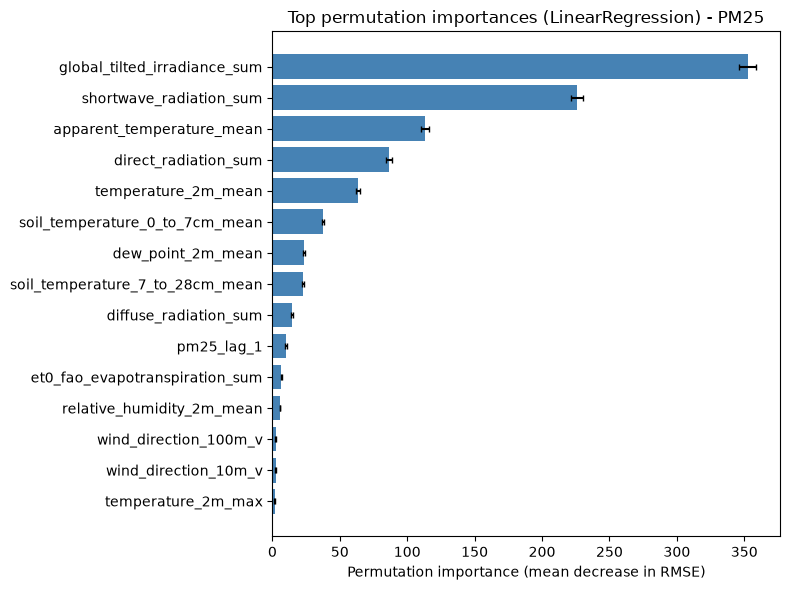


PM10 (RandomForest, permutation importance on test set)


,feature,importance_mean,importance_std
0,pm10_lag_1,14.5560,0.5758
48,soil_temperature_0_to_7cm_mean,1.7479,0.2501
27,cloud_cover_low_mean,0.6221,0.0689
28,cloud_cover_mid_mean,0.3287,0.0383
13,temperature_2m_max,0.1544,0.0227
47,vapour_pressure_deficit_mean,0.1103,0.0262
29,cloud_cover_high_mean,0.1091,0.0293
34,sunshine_duration_sum,0.1043,0.0236
16,relative_humidity_2m_max,0.0999,0.0325
53,soil_moisture_7_to_28cm_mean,0.0816,0.0249


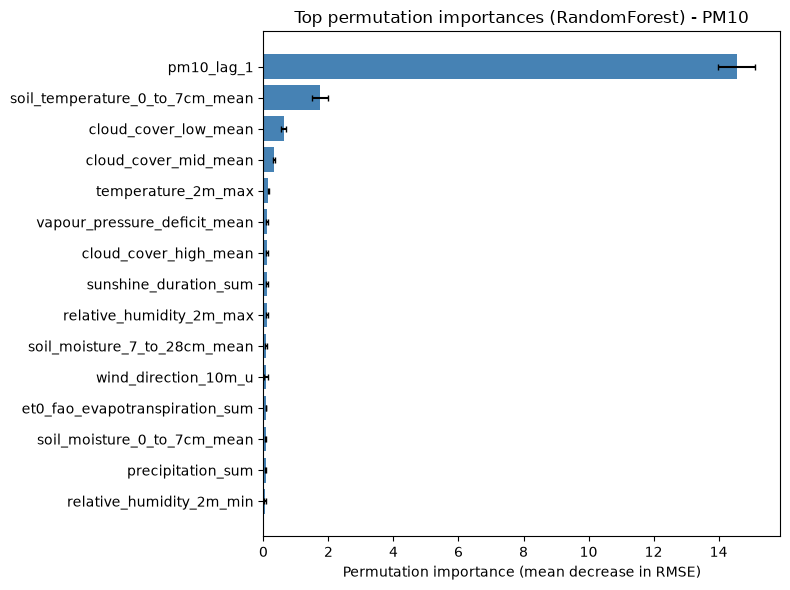

In [16]:
perm_importances = {}

for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    best_model = results_by_key[(pollutant, "same_day")]["RMSE"].idxmin()
    model = entry["models"][best_model]

    perm = permutation_importance(
        model,
        entry["X_test"],
        entry["y_test"],
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1,
    )

    entry["importance"] = perm.importances_mean

    perm_df = pd.DataFrame({
        "feature": entry["X_test"].columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    }).sort_values("importance_mean", ascending=False)

    perm_importances[pollutant] = perm_df

    print(f"\n{pollutant.upper()} ({best_model}, permutation importance on test set)")
    display(perm_df.head(15).round(4))

    plt.figure(figsize=(8, 6))
    plot_df = perm_df.head(15).iloc[::-1]
    plt.barh(plot_df["feature"], plot_df["importance_mean"], xerr=plot_df["importance_std"],
             color="steelblue", capsize=2)
    plt.xlabel("Permutation importance (mean decrease in RMSE)")
    plt.title(f"Top permutation importances ({best_model}) - {pollutant.upper()}")
    plt.tight_layout()
    plt.show()



PM25 standardized LR coefficients (sanity check)


,feature,std_coef
global_tilted_irradiance_sum,global_tilted_irradiance_sum,-11.7955
shortwave_radiation_sum,shortwave_radiation_sum,7.6550
apparent_temperature_mean,apparent_temperature_mean,4.0795
direct_radiation_sum,direct_radiation_sum,3.1154
temperature_2m_mean,temperature_2m_mean,-2.3931
soil_temperature_0_to_7cm_mean,soil_temperature_0_to_7cm_mean,-1.4687
dew_point_2m_mean,dew_point_2m_mean,-1.4232
diffuse_radiation_sum,diffuse_radiation_sum,1.0980
soil_temperature_7_to_28cm_mean,soil_temperature_7_to_28cm_mean,0.9591
pm25_lag_1,pm25_lag_1,0.4823


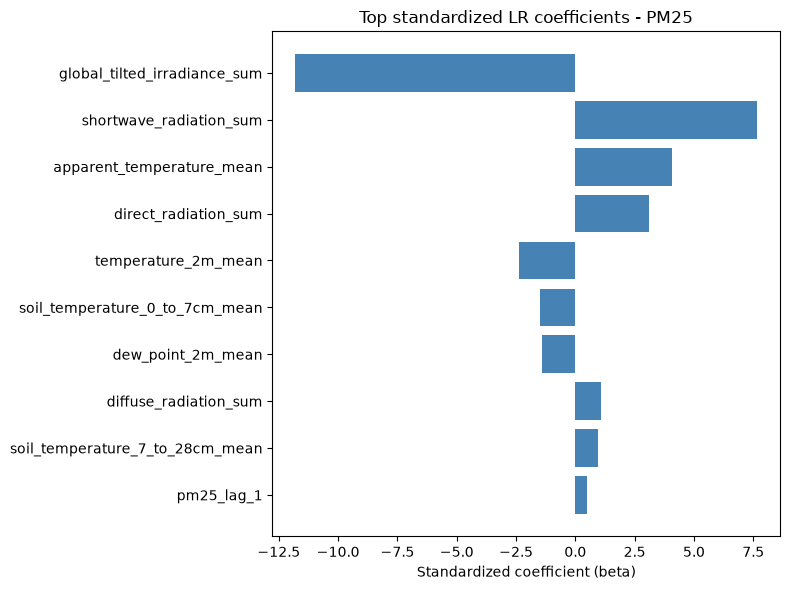


PM10 standardized LR coefficients (sanity check)


,feature,std_coef
global_tilted_irradiance_sum,global_tilted_irradiance_sum,-59.2315
shortwave_radiation_sum,shortwave_radiation_sum,39.0904
direct_radiation_sum,direct_radiation_sum,16.8205
diffuse_radiation_sum,diffuse_radiation_sum,5.2092
apparent_temperature_mean,apparent_temperature_mean,3.3855
soil_temperature_0_to_7cm_mean,soil_temperature_0_to_7cm_mean,-2.4912
temperature_2m_mean,temperature_2m_mean,-2.3481
soil_temperature_7_to_28cm_mean,soil_temperature_7_to_28cm_mean,1.7934
dew_point_2m_mean,dew_point_2m_mean,-0.9215
et0_fao_evapotranspiration_sum,et0_fao_evapotranspiration_sum,0.6748


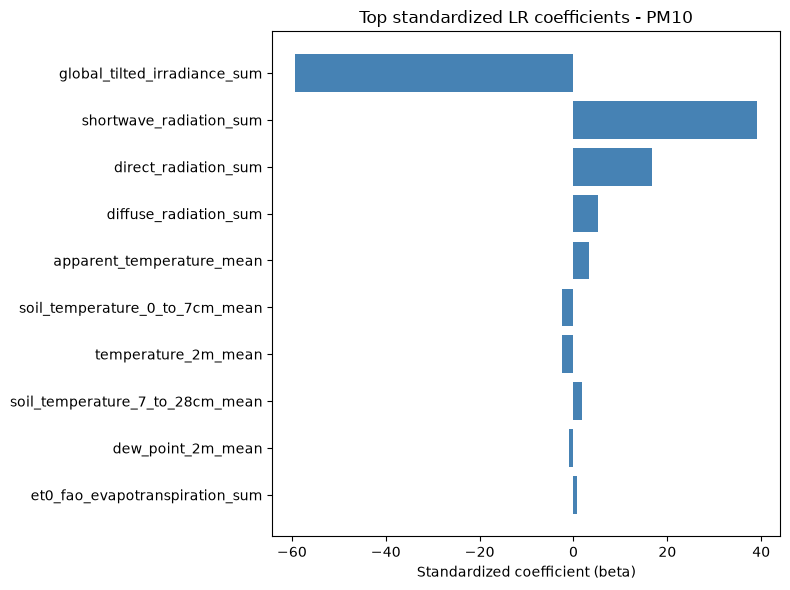

In [17]:
lr_std_coefs = {}

for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    lr = entry["models"]["LinearRegression"]

    beta = lr.coef_ * entry["X_train"].std() / entry["y_train"].std()

    beta_df = pd.DataFrame({
        "feature": entry["X"].columns,
        "std_coef": beta,
        "abs_std_coef": np.abs(beta),
    }).sort_values("abs_std_coef", ascending=False)

    lr_std_coefs[pollutant] = beta_df

    print(f"\n{pollutant.upper()} standardized LR coefficients (sanity check)")
    display(beta_df.drop(columns="abs_std_coef").head(10).round(4))

    plt.figure(figsize=(8, 6))
    plot_df = beta_df.head(10).iloc[::-1]
    plt.barh(plot_df["feature"], plot_df["std_coef"], color="steelblue")
    plt.xlabel("Standardized coefficient (beta)")
    plt.title(f"Top standardized LR coefficients - {pollutant.upper()}")
    plt.tight_layout()
    plt.show()


In [18]:
def get_factor_groups(pollutant, feature_names):
    return {
        "Previous pollution (lag)": [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS],
        "Previous pollution (rolling)": [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS],
        "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
        "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
        "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
        "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
        "Pressure": [c for c in feature_names if "pressure" in c],
        "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
        "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
        "Soil": [c for c in feature_names if c.startswith("soil")],
        "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
        "Weather code": [c for c in feature_names if "weather_code" in c],
    }


In [19]:
def group_importance(importance, feature_names, factor_groups):
    factor_importance = []

    for factor, cols in factor_groups.items():
        present = [c for c in cols if c in feature_names]
        if not present:
            continue

        vals = [importance[feature_names.index(c)] for c in present]
        factor_importance.append({
            "factor": factor,
            "n_features": len(present),
            "importance_sum": float(np.sum(vals)),
            "importance_max": float(np.max(vals)),
        })

    return pd.DataFrame(factor_importance).sort_values("importance_sum", ascending=False)


In [20]:
factor_tables = {}

for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    feature_names = list(entry["X"].columns)
    factor_df = group_importance(entry["importance"], feature_names, get_factor_groups(pollutant, feature_names))
    factor_tables[pollutant] = factor_df

    print(f"\n{pollutant.upper()} (permutation importance summed by factor)")
    display(factor_df.round(4))



PM25 (permutation importance summed by factor)


,factor,n_features,importance_sum,importance_max
7,Clouds & radiation,9,335.2386,226.0042
2,Temperature,9,262.1338,113.1702
9,Soil,8,61.4796,37.4741
4,Wind,24,13.5298,2.4845
0,Previous pollution (lag),3,10.9579,10.1252
3,Humidity,4,7.3649,5.5288
1,Previous pollution (rolling),4,2.0377,1.0340
6,Pressure,5,0.8109,0.6760
5,Precipitation,5,0.6942,0.5981
8,Season / calendar,5,0.5522,0.4711



PM10 (permutation importance summed by factor)


,factor,n_features,importance_sum,importance_max
0,Previous pollution (lag),3,14.1746,14.5560
9,Soil,8,1.9698,1.7479
2,Temperature,9,1.8145,1.7479
7,Clouds & radiation,9,1.3075,0.6221
3,Humidity,4,0.2960,0.1103
6,Pressure,5,0.2098,0.1103
5,Precipitation,5,0.1132,0.0652
11,Weather code,1,0.0034,0.0034
10,Wind category,3,0.0007,0.0004
8,Season / calendar,5,-0.2042,0.0093


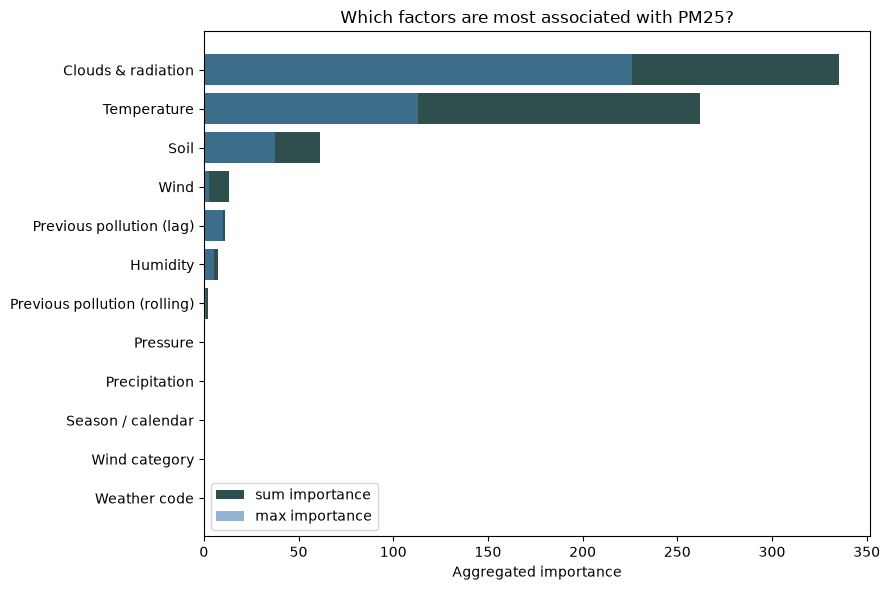

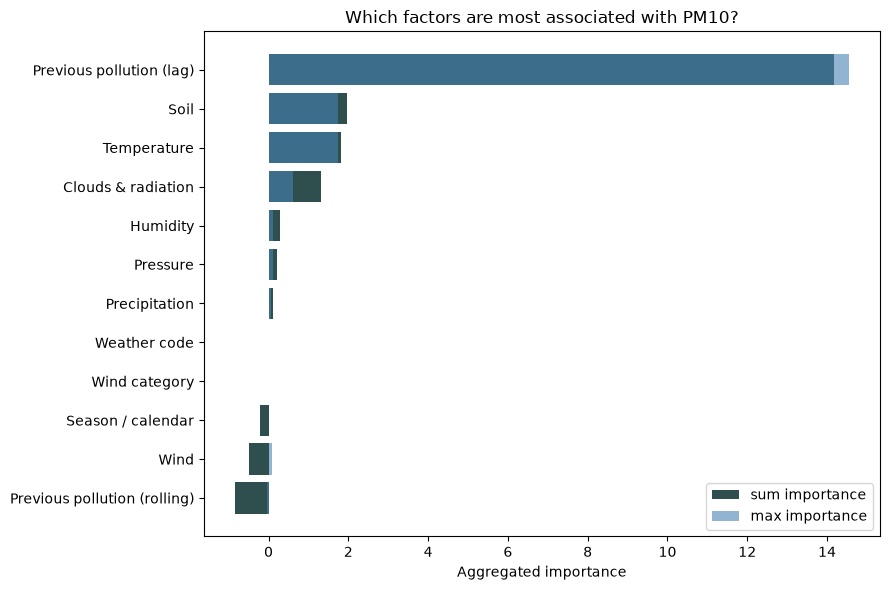

In [21]:
for pollutant in POLLUTANTS:
    factor_df = factor_tables[pollutant]

    plt.figure(figsize=(9, 6))
    plot_df = factor_df.iloc[::-1]
    plt.barh(plot_df["factor"], plot_df["importance_sum"], color="darkslategray", label="sum importance")
    plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
    plt.xlabel("Aggregated importance")
    plt.title(f"Which factors are most associated with {pollutant.upper()}?")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [22]:
for pollutant in POLLUTANTS:
    METRICS_OUT = PROCESSED_DIR / f"regression_metrics_{pollutant}.parquet"
    PRED_OUT = PROCESSED_DIR / f"regression_predictions_{pollutant}.parquet"

    results_by_key[(pollutant, "same_day")].to_parquet(METRICS_OUT)
    comparisons[(pollutant, "same_day")].to_parquet(PRED_OUT, index=False)

    print(f"Saved: {METRICS_OUT.name} (same_day weather variant)")
    print(f"Saved: {PRED_OUT.name} (same_day weather variant)")


Saved: regression_metrics_pm25.parquet (same_day weather variant)
Saved: regression_predictions_pm25.parquet (same_day weather variant)
Saved: regression_metrics_pm10.parquet (same_day weather variant)
Saved: regression_predictions_pm10.parquet (same_day weather variant)


In [23]:
TEMP_FEATURES = ["temperature_2m_mean", "dew_point_2m_mean", "apparent_temperature_mean",
                 "soil_temperature_0_to_7cm_mean", "soil_temperature_7_to_28cm_mean"]

for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    model_df = entry["model_df"]

    rows = []
    for col in TEMP_FEATURES:
        r_overall = model_df[col].corr(model_df[pollutant])
        r_by_season = model_df.groupby("season").apply(lambda g: g[col].corr(g[pollutant]))
        rows.append({
            "feature": col,
            "corr_overall": r_overall,
            "corr_mean_within_season": r_by_season.mean(),
            "corr_min_within_season": r_by_season.min(),
            "corr_max_within_season": r_by_season.max(),
            "abs_gap": abs(r_overall) - abs(r_by_season).mean(),
        })

    season_corr_df = pd.DataFrame(rows).sort_values("abs_gap", ascending=False)

    print(f"\n{pollutant.upper()}: temperature correlation overall vs within-season")
    display(season_corr_df.round(3))
    print("Large abs_gap means the overall correlation is mostly a season proxy, not a within-season weather effect")



PM25: temperature correlation overall vs within-season


,feature,corr_overall,corr_mean_within_season,corr_min_within_season,corr_max_within_season,abs_gap
0,temperature_2m_mean,-0.433,-0.076,-0.228,0.205,0.254
2,apparent_temperature_mean,-0.434,-0.087,-0.287,0.195,0.250
1,dew_point_2m_mean,-0.448,-0.196,-0.478,0.027,0.239
3,soil_temperature_0_to_7cm_mean,-0.494,-0.226,-0.435,0.203,0.166
4,soil_temperature_7_to_28cm_mean,-0.488,-0.226,-0.435,0.208,0.159


Large abs_gap means the overall correlation is mostly a season proxy, not a within-season weather effect

PM10: temperature correlation overall vs within-season


,feature,corr_overall,corr_mean_within_season,corr_min_within_season,corr_max_within_season,abs_gap
0,temperature_2m_mean,-0.387,-0.043,-0.230,0.304,0.192
2,apparent_temperature_mean,-0.384,-0.043,-0.240,0.324,0.179
1,dew_point_2m_mean,-0.383,-0.146,-0.323,0.150,0.162
4,soil_temperature_7_to_28cm_mean,-0.466,-0.280,-0.515,0.144,0.114
3,soil_temperature_0_to_7cm_mean,-0.473,-0.254,-0.543,0.214,0.112


Large abs_gap means the overall correlation is mostly a season proxy, not a within-season weather effect
